# Assimetrias entre B⁻ e B⁺ com dados simulados

Esse notebook acompanha o projeto. Os dados são todos simulados: eu escolho a assimetria, sorteio as contagens e vejo se o estimador, os intervalos e os testes devolvem o que eu coloquei. **Não é medida de física**, e os 5 % e 10 % dos cenários são só valores que eu escolhi.

As simulações grandes (2000 repetições × 9 configurações) já estão salvas em `resultados/`; o `rodar_tudo.py` refaz tudo do zero. Aqui eu refaço só o que é rápido e leio o resto.

In [1]:
import csv
import math
from IPython.display import Image, display

from src.geracao import ler_config, criar_geradores, medias_esperadas, gerar_contagens, A_total_esperado
from src.estimadores import soma, assimetria, assimetria_total, sigma_A
from src.intervalos import intervalo_A
from src.mc import carregar_contagens, nome_arquivo, metricas_assimetria
from src.cobertura import cobertura_exata
from src.testes import fp_exato, poder_exato

cfg = ler_config()
pesos = cfg["pesos"]
print("regiões:", cfg["k"], "| N_exp:", cfg["N_exp"], "| M:", cfg["M"])

regiões: 10 | N_exp: [1000, 10000, 100000] | M: 2000


## 1. Um experimento só

Cenário `global` (A = 0,05 em todas as regiões) com N = 10 000. Em cada região o esperado é mu⁻ = 525 e mu⁺ = 475.

In [2]:
rng = criar_geradores(cfg["semente_mae"], 20)[0]
A = cfg["cenarios"]["global"]
mu_m, mu_p = medias_esperadas(10000, pesos, A)
print("mu- =", mu_m[0], " mu+ =", mu_p[0])

n_m, n_p = gerar_contagens(mu_m, mu_p, rng)
print("reg    N-    N+    A_hat   Wilson             Clopper-Pearson")
for i in range(10):
    a = assimetria(n_m[i], n_p[i])
    w = intervalo_A(n_m[i], n_p[i], "wilson")
    c = intervalo_A(n_m[i], n_p[i], "clopper_pearson")
    print(str(i + 1).rjust(3), str(n_m[i]).rjust(5), str(n_p[i]).rjust(5), str(round(a, 4)).rjust(8),
          "  [", round(w[0], 3), ",", round(w[1], 3), "]  [", round(c[0], 3), ",", round(c[1], 3), "]")
print("total:", round(assimetria_total(n_m, n_p), 4), "| esperado:", A_total_esperado(pesos, A))

mu- = 525.0  mu+ = 475.0
reg    N-    N+    A_hat   Wilson             Clopper-Pearson
  1   517   516    0.001   [ -0.06 , 0.062 ]  [ -0.061 , 0.063 ]
  2   544   483   0.0594   [ -0.002 , 0.12 ]  [ -0.003 , 0.121 ]
  3   503   479   0.0244   [ -0.038 , 0.087 ]  [ -0.039 , 0.088 ]
  4   551   515   0.0338   [ -0.026 , 0.094 ]  [ -0.027 , 0.095 ]
  5   493   499   -0.006   [ -0.068 , 0.056 ]  [ -0.069 , 0.057 ]
  6   518   466   0.0528   [ -0.01 , 0.115 ]  [ -0.011 , 0.116 ]
  7   494   531  -0.0361   [ -0.097 , 0.025 ]  [ -0.098 , 0.026 ]
  8   532   469   0.0629   [ 0.001 , 0.124 ]  [ 0.0 , 0.125 ]
  9   520   519    0.001   [ -0.06 , 0.062 ]  [ -0.061 , 0.063 ]
 10   527   422   0.1106   [ 0.047 , 0.173 ]  [ 0.046 , 0.175 ]
total: 0.0297 | esperado: 0.05


## 2. Repetindo 2000 vezes

Mesmo cenário, lendo as contagens salvas. O desvio do total tem que ficar perto de sqrt((1 − A²)/T), e o pull perto de uma normal padrão.

viés do total: -3e-05 +- 0.00022
desvio observado: 0.00981 | previsto: 0.00999
pull (média e desvio): -0.003 0.982


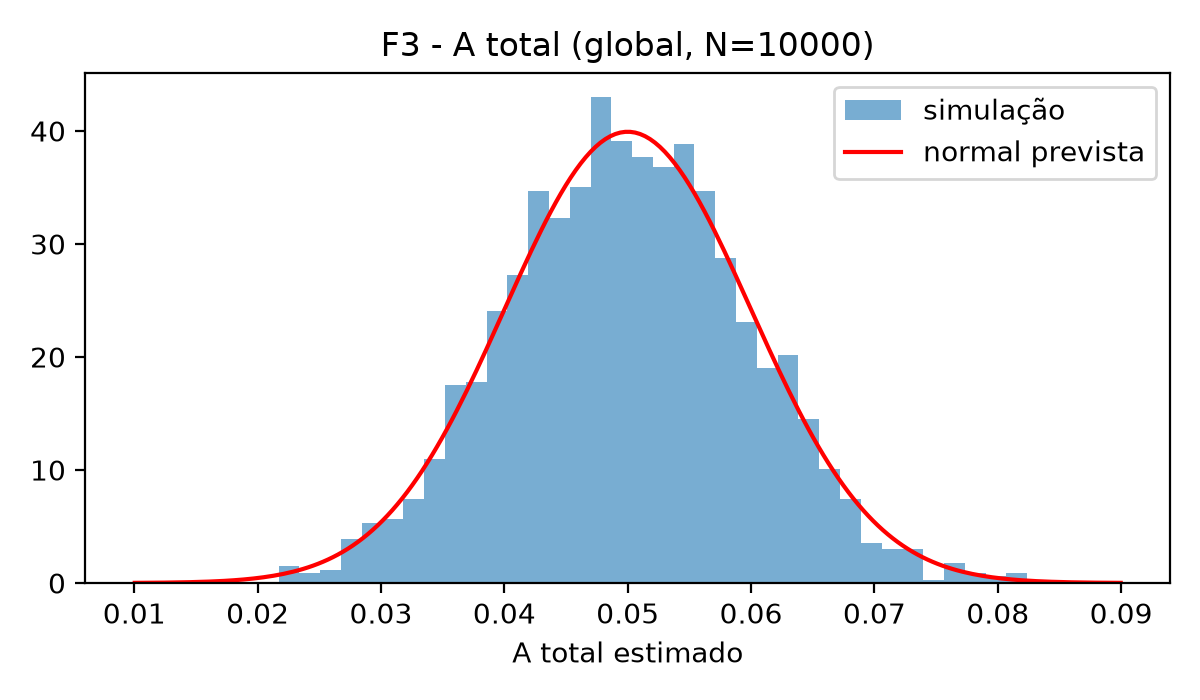

In [3]:
todos_m, todos_p = carregar_contagens(nome_arquivo("global", 10000))
m = metricas_assimetria(todos_m, todos_p, A, pesos)
tot = m[10]
print("viés do total:", round(tot["vies"], 5), "+-", round(tot["erro_vies"], 5))
print("desvio observado:", round(tot["desvio"], 5), "| previsto:", round(tot["previsto"], 5))
print("pull (média e desvio):", round(tot["pull_media"], 3), round(tot["pull_desvio"], 3))
display(Image("figuras/F3_hist_total_global.png", width=480))

## 3. Intervalos e cobertura

Cobertura exata (soma sobre k, sem sorteio nenhum) com A = 0. No meio Wald e Wilson dão quase o mesmo; o Clopper–Pearson fica acima de 95 %. A curva mostra o que acontece conforme A se aproxima de ±1.

T =   100  wald / wilson / clopper-pearson: [94.31, 94.31, 96.48]
T =  1000  wald / wilson / clopper-pearson: [94.63, 94.63, 95.37]
T = 10000  wald / wilson / clopper-pearson: [94.88, 94.88, 95.12]



metodo | cob_estresse_mc_pct | cob_estresse_exata_pct | min_curva_T100_pct
wald | 62.8 | 62.74 | 63.34
wilson | 96.0 | 95.91 | 92.06
clopper_pearson | 99.0 | 99.04 | 95.18


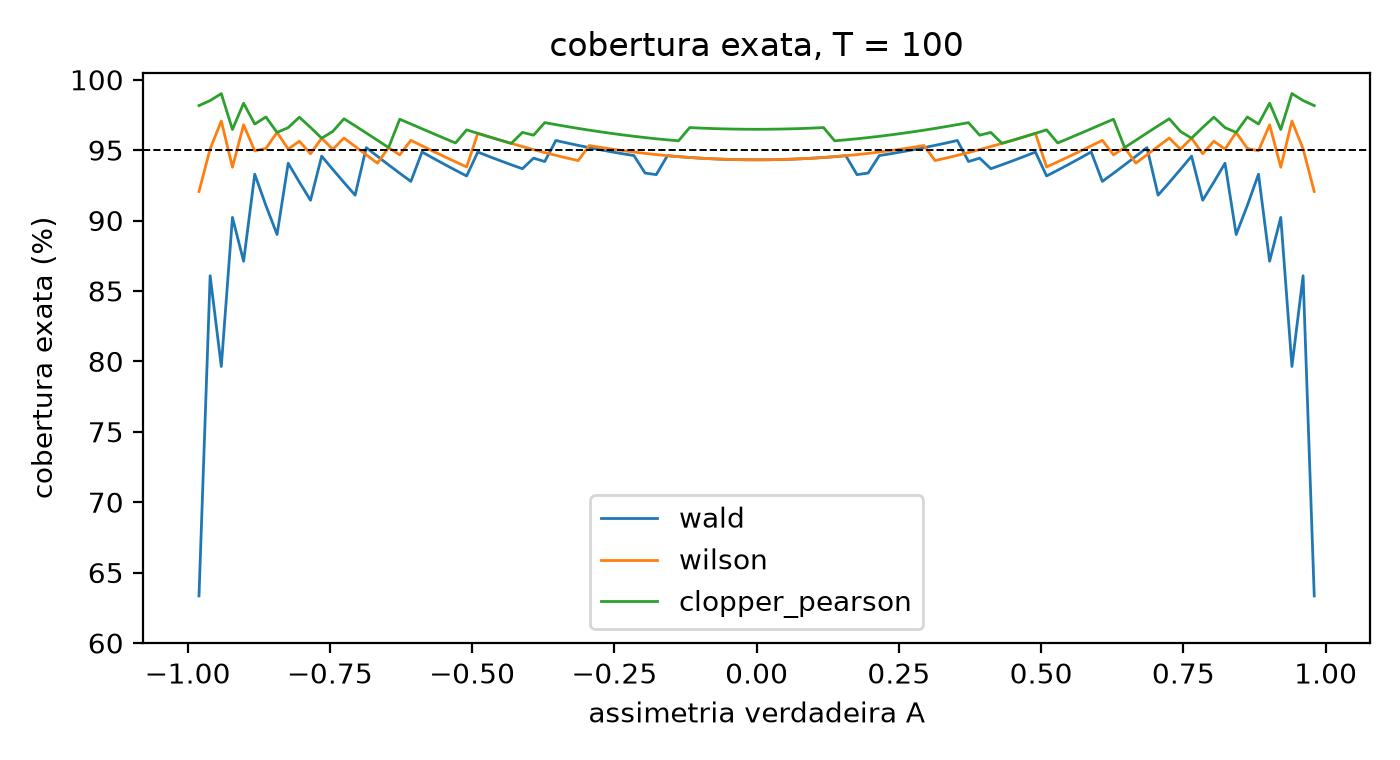

In [4]:
for T in [100, 1000, 10000]:
    vals = []
    for metodo in ["wald", "wilson", "clopper_pearson"]:
        vals.append(round(100 * cobertura_exata(T, 0.5, metodo), 2))
    print("T =", str(T).rjust(5), " wald / wilson / clopper-pearson:", vals)
print()
arq = open("resultados/cobertura_estresse.csv", encoding="utf-8")
for linha in csv.reader(arq):
    print(" | ".join(linha))
arq.close()
display(Image("figuras/F6_cobertura_curva_T100.png", width=560))

## 4. O total e a compensação local

No cenário `compensacao` o total dá zero (+0,10 numa metade, −0,10 na outra). O teste do total rejeita só uns 5 %, que é o falso positivo. O χ² de homogeneidade enxerga a diferença entre as regiões.

cenário      N       total  bonferroni  max|z|  chi2_0  chi2_hom
compensacao  1000     0.051     0.2455   0.292   0.529   0.5535
compensacao  10000    0.046        1.0     1.0     1.0      1.0
compensacao  100000  0.0505        1.0     1.0     1.0      1.0

falso positivo exato do teste bilateral (5 %), n = 100, 1000, 10000: [3.52, 4.63, 4.88]


poder exato com T = 1000 e A = 0,05: 0.3407


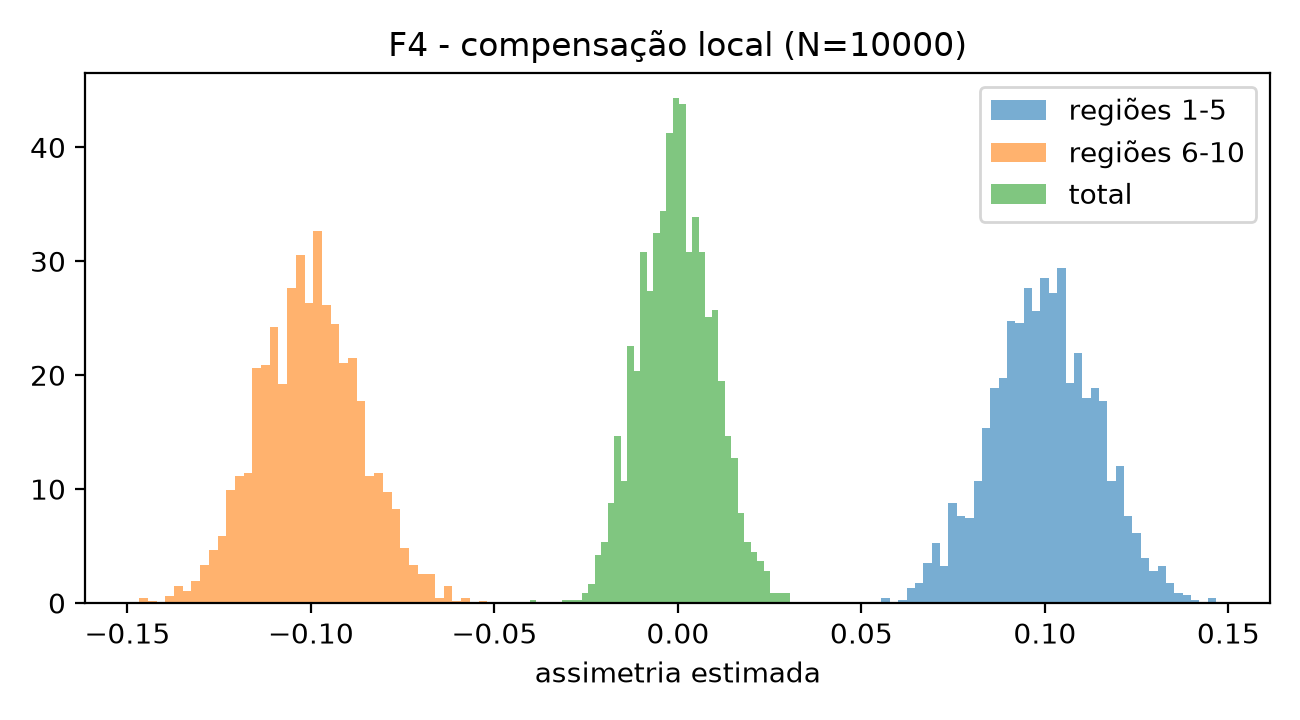

In [5]:
arq = open("resultados/metricas.csv")
print("cenário      N       total  bonferroni  max|z|  chi2_0  chi2_hom")
for linha in csv.DictReader(arq):
    if linha["cenario"] == "compensacao":
        print(linha["cenario"].ljust(12), linha["N"].ljust(7), linha["rej_total"].rjust(6), linha["rej_bonferroni"].rjust(10),
              linha["rej_maxz"].rjust(7), linha["rej_chi2_0"].rjust(7), linha["rej_chi2_hom"].rjust(8))
arq.close()
print()
fps = []
for n in [100, 1000, 10000]:
    fps.append(round(100 * fp_exato(n, 0.05), 2))
print("falso positivo exato do teste bilateral (5 %), n = 100, 1000, 10000:", fps)
print("poder exato com T = 1000 e A = 0,05:", round(poder_exato(1000, 0.05, 0.05), 4))
display(Image("figuras/F4_compensacao.png", width=480))

## 5. Eficiência diferente

Se B⁻ e B⁺ são detectados com eficiências diferentes (a = -0,02), aparece assimetria mesmo com A = 0. Testando a fórmula inversa direto, ela devolve A sem erro; nos sorteios com a exato, o viés corrigido zera até o ruído estatístico (~10⁻⁴ em N = 10⁵). Quando a tem incerteza absoluta σ_a = 0,005 (0,5 ponto percentual), o desvio do A corrigido em N = 10⁵ sobe de 0,31 % para 0,60 %.

A_obs com A = 0: -0.02 | depois de corrigir: 0.0

N | sigma_a | A_obs_medio | sig_aparente | taxa_falsa_descoberta | media_corrigida | desvio_corrigido | desvio_previsto
1000 | 0.0 | -0.02078 | -0.66 | 0.097 | -0.0008 | 0.03122 | 0.03162
10000 | 0.0 | -0.01964 | -1.96 | 0.496 | 0.00036 | 0.01006 | 0.01
100000 | 0.0 | -0.01997 | -6.32 | 1.0 | 3e-05 | 0.00314 | 0.00316
100000 | 0.005 | -0.02007 | -6.35 | 1.0 | -0.00011 | 0.00596 | 0.00592


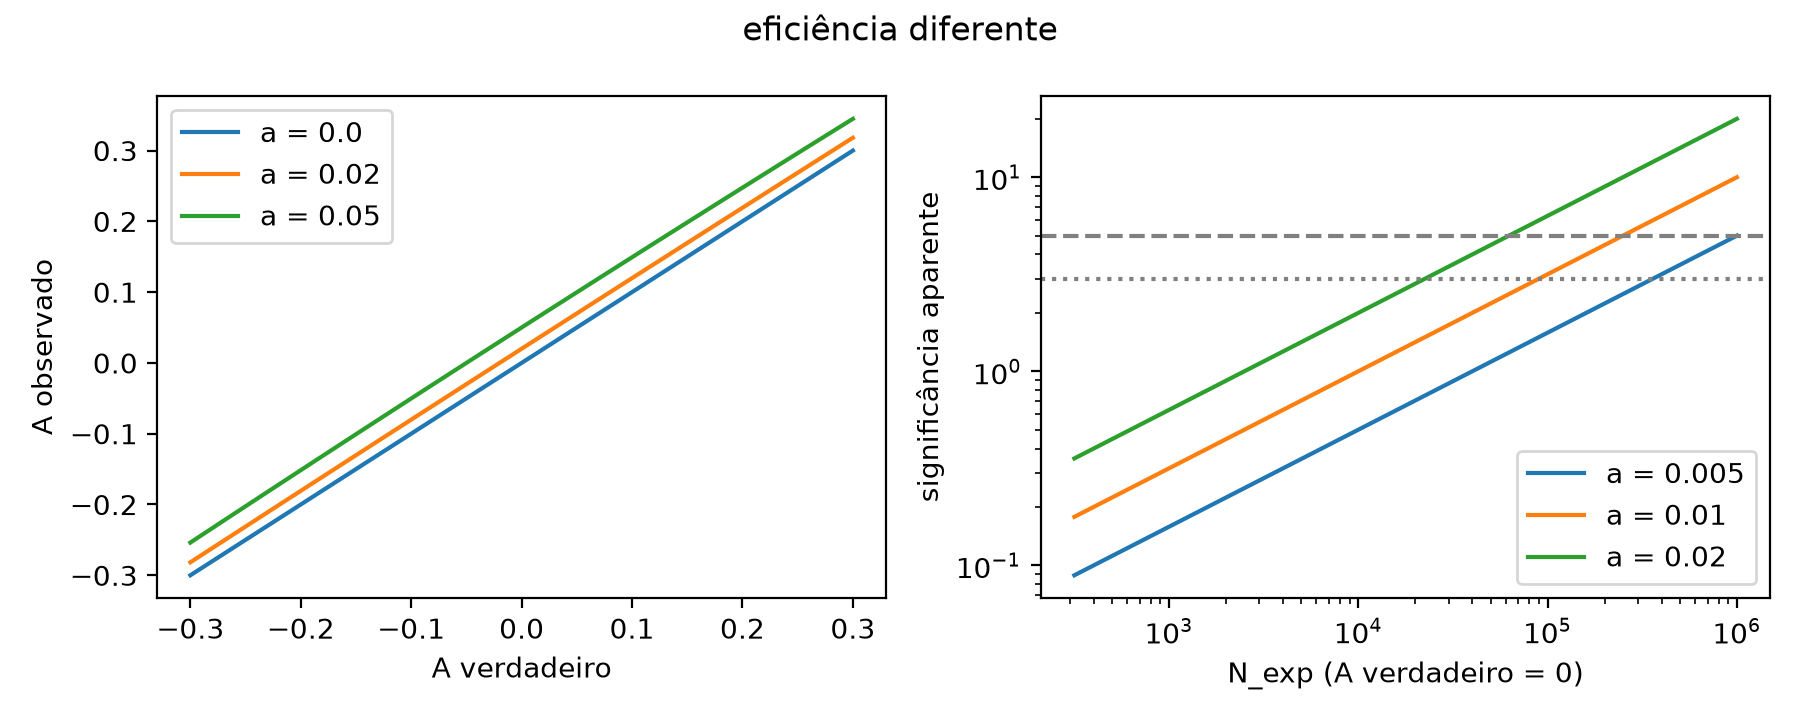

In [6]:
from src.eficiencia import A_obs, corrigir
a = cfg["a_eficiencia"]
print("A_obs com A = 0:", A_obs(0, a), "| depois de corrigir:", corrigir(A_obs(0, a), a))
print()
arq = open("resultados/eficiencia_resumo.csv", encoding="utf-8")
for linha in csv.reader(arq):
    print(" | ".join(linha))
arq.close()
display(Image("figuras/F8_eficiencia.png", width=640))

## 6. Etapas 2 e 3 (brinquedo)

Na etapa 2, uso um perfil gaussiano 1D em m(p p̄) com os pesos cinemáticos calculados do espaço de fase e comparo a largura da janela b/s contra a significância esperada (pico em b*/s ≈ 2,8 no modelo idealizado sem fundo nem interferência). Na etapa 3, gero um mapa de S no plano de Dalitz de B± → p p̄ K± com dois blocos gaussianos 2D em (s12, s23) de sinais opostos (+0,30 e −0,15) para que se anulem quase por completo na contagem total (média esperada dos perfis sobre a região cinemática ≈ −0,003 ± 0,007 para N = 20 000, dando −0,0003 no sorteio). Massas do PDG, e o S é baseado no método de Bediaga et al. (2009) (onde a razão global α = N⁻/N⁺ já desconta assimetrias globais de produção ou detecção).

cenario | n_bins | A_total | p_total | p_chi2_hom | menor_S | maior_S | maior_abs_S
um_bloco | 48 | 0.0331 | 3e-06 | 2.1088835012614934e-12 | -2.09 | 5.88 | 5.88
dois_blocos | 48 | -0.0003 | 0.971797 | 1.3163182872047767e-20 | -3.95 | 6.17 | 6.17


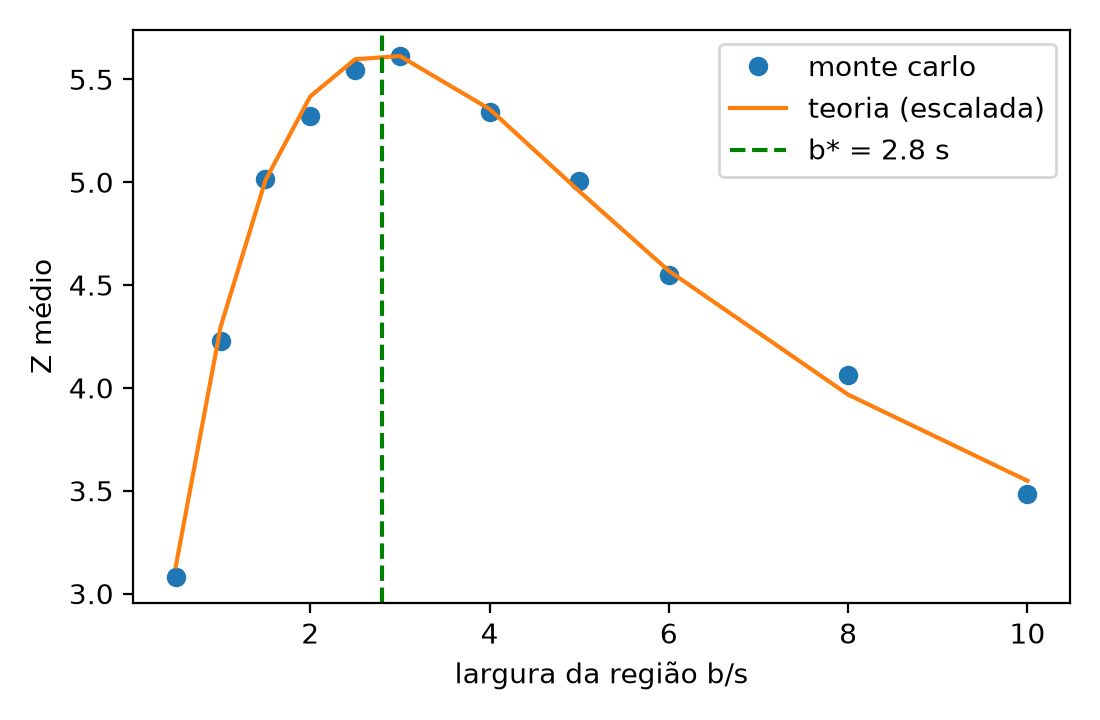

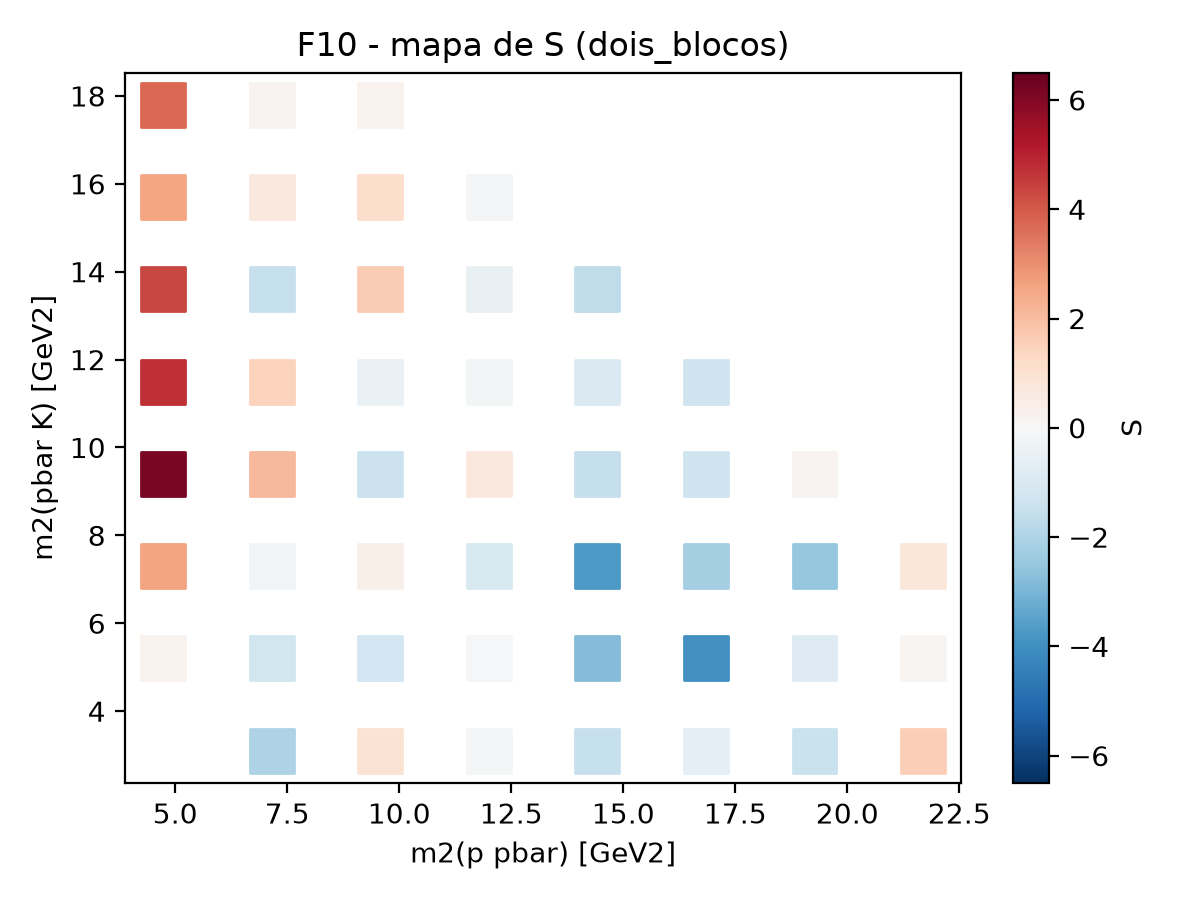

In [7]:
arq = open("resultados/etapa3_dalitz.csv", encoding="utf-8")
for linha in csv.reader(arq):
    print(" | ".join(linha))
arq.close()
display(Image("figuras/F9_largura.png", width=420))
display(Image("figuras/F10_mapa_dois_blocos.png", width=420))

## 7. Tabela de verificação

Cada linha compara um método com uma referência independente (conta feita à mão, soma exata, scipy).

In [8]:
for nome in ["resultados/verificacao.csv", "resultados/verificacao_etapa3.csv"]:
    arq = open(nome, encoding="utf-8")
    for linha in csv.reader(arq):
        print(" | ".join(linha))
    arq.close()
    print()

item | descricao | valor | criterio | passou
1 | convenção de sinal | 525/475 dá +0.05, trocando dá -0.05 | igualdade | sim
2 | casos feitos à mão | (3,1) (7,7) (5,0) (0,0) | igualdade; (0,0) indefinido | sim
3 | total = média ponderada por T_i | maior diferença 3.469446951953614e-18 | < 1e-12 | sim
4 | soma dos mu = N_exp e A_total esperado | mu-=525 e mu+=475 no exemplo | igualdade | sim
5 | média e variância das contagens (global, N=1e4) | fora do critério: 0 de 40 | <= 2 | sim
6 | viés de A_i e do total | fora de 3 sigma: 0 de 99 | <= 2 | sim
7 | dispersão contra sqrt((1-A^2)/T) | fora de 5%: 1 de 99 | <= 2 | sim
8 | escala 1/raiz(N): desvio(1e3)/desvio(1e5) | [9.76, 10.17, 10.04] | perto de 10 (+-1) | sim
9 | Wilson e Clopper-Pearson contra o scipy | maior diferença 2.220446049250313e-14 | < 1e-9 | sim
10 | casos extremos | T=0, k=0, k=n, limites em [-1, 1] | sem divisão por zero | sim
11 | cobertura monte carlo contra soma exata | fora de 3 sigma: 0 de 54 | <= 4 | sim
12 | falso 

## O que isso não é

- Não tem dado real nem medida do LHCb. Tudo vem de um gerador Poisson com parâmetros que eu conheço.
- Resultado compatível com zero não prova que CP se conserva: pode ser só amostra pequena.
- As etapas 2 e 3 são um brinquedo (sem ressonâncias, fundo ou interferência).